In [7]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pipeline.endpoints import DB_PATH

In [9]:
con = duckdb.connect(str(DB_PATH))

with con:
    # 1. Drop the table safely
    results_df = con.execute("SELECT * FROM clean.int_play_by_play WHERE (shot_distance IS NOT NULL and shot_angle IS NOT NULL) AND game_id = 2026020017;").df()

In [10]:
results_df.head()

,event_key,sort_order,game_id,event_id,period,period_type,time_in_period,event_period_seconds,event_game_seconds,type_desc_key,...,event_skaters,opp_skaters,is_empty_net_against,strength_state,skater_state,x_norm,y_norm,shot_distance,shot_angle,loaded_at
0,2026020017 - 61,19,2026020017,61,1,REG,00:41,41,41,shot-on-goal,...,5,5,False,EV,5v5,92,19,19.235,98.973,2026-11-12 19:59:01.703829-05:00
1,2026020017 - 63,21,2026020017,63,1,REG,00:56,56,56,shot-on-goal,...,5,5,False,EV,5v5,75,-34,36.770,67.620,2026-11-12 19:59:01.703829-05:00
2,2026020017 - 64,22,2026020017,64,1,REG,01:00,60,60,missed-shot,...,5,5,False,EV,5v5,60,0,29.000,0.000,2026-11-12 19:59:01.703829-05:00
3,2026020017 - 66,24,2026020017,66,1,REG,01:11,71,71,shot-on-goal,...,5,5,False,EV,5v5,82,-13,14.765,61.699,2026-11-12 19:59:01.703829-05:00
4,2026020017 - 91,49,2026020017,91,1,REG,03:12,192,192,missed-shot,...,5,5,False,EV,5v5,84,16,16.763,72.646,2026-11-12 19:59:01.703829-05:00


In [13]:
results_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype                           
---  ------                    --------------  -----                           
 0   event_key                 88 non-null     str                             
 1   sort_order                88 non-null     int32                           
 2   game_id                   88 non-null     int64                           
 3   event_id                  88 non-null     int64                           
 4   period                    88 non-null     int64                           
 5   period_type               88 non-null     str                             
 6   time_in_period            88 non-null     str                             
 7   event_period_seconds      88 non-null     int32                           
 8   event_game_seconds        88 non-null     int64                           
 9   type_desc_key          

/Users/markgranatire/.venvs/py313/lib/python3.13/site-packages/pandas/plotting/_matplotlib/core.py:1390: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


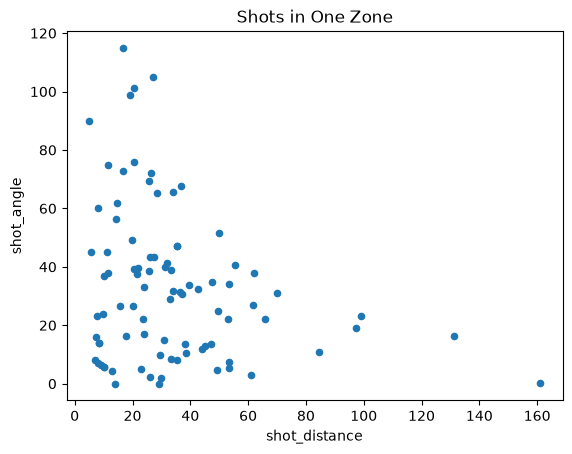

In [11]:
results_df.plot.scatter(
    x='shot_distance',
    y='shot_angle',
    colormap='viridis',
    title='Shots in One Zone'
)
plt.show()

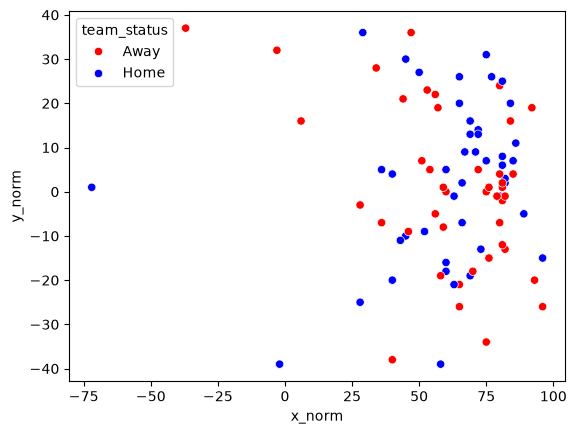

In [17]:
import seaborn as sns
import numpy as np
results_df['team_status'] = np.where(
    results_df['event_team_abbrev'] == results_df['home_team_abbrev'], 'Home', 'Away'
)

# 2. Plot using the new column in 'hue'
sns.scatterplot(
    data=results_df,
    x='x_norm',
    y='y_norm',
    hue='team_status',
    palette={'Home': 'blue', 'Away': 'red'},
)

plt.show()